In [39]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

sz = qt.sigmaz()
sm = qt.sigmam()
sp = qt.sigmap()
sx = qt.sigmax()

pi = np.pi
c = 3e8
f_d = 2e9
detuning = 50e6
gamma0 = 1e6
N = 5

er = 6.38
vp = c / np.sqrt(er)

In [ ]:
def Gamma_calc(f_d,w,gamma,N, v,rabi):
    lambda_d = v / f_d
    delta_x = 3 * lambda_d / 2
    w0_pm = w
    w0_p = w - rabi
    w0_m = w + rabi

    phi_pm = 2*pi * w0_pm * delta_x / v
    phi_p = 2*pi * w0_p * delta_x / v
    phi_m = 2*pi * w0_m * delta_x / v
    gamma_freq_pm = gamma * np.square(w/(w0_pm))
    gamma_freq_p = gamma * np.square(w/(w0_p))
    gamma_freq_m = gamma * np.square(w/(w0_m))

    Gamma_pm = np.zeros_like(phi_pm, dtype=float)
    Gamma_p = np.zeros_like(phi_pm, dtype=float)
    Gamma_m = np.zeros_like(phi_pm, dtype=float)

    Gamma_pm = 2 * gamma_freq_pm * np.square(1 + 2*np.cos(phi_pm) + 2*np.cos(2*phi_pm))
    Gamma_p = 2 * gamma_freq_p * np.square(1 + 2*np.cos(phi_p) + 2*np.cos(2*phi_p))
    Gamma_m = 2 * gamma_freq_m * np.square(1 + 2*np.cos(phi_m) + 2*np.cos(2*phi_m))
    return Gamma_pm, Gamma_p, Gamma_m, phi_pm

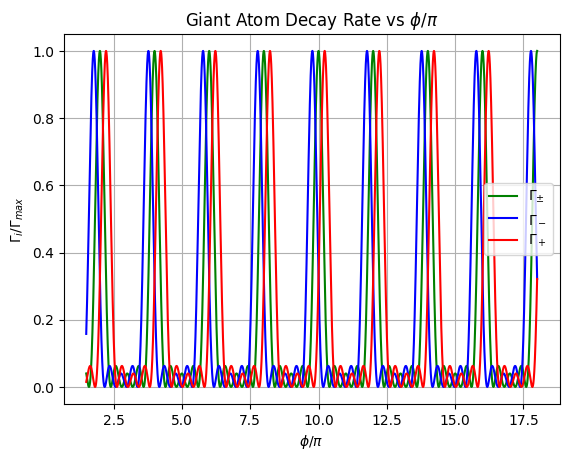

In [64]:
freq_q = np.linspace(1e9, 12e9, 100000)

rabi = 150e6
Gamma_pm, Gamma_p, Gamma_m, phi = Gamma_calc(f_d, freq_q, gamma0, N, vp, rabi)
lambda_d = vp / f_d
delta_x = 3 * lambda_d / 2
phi_plot = 2 * np.pi * freq_q * delta_x / vp
# Gamma_zeros = np.min(Gamma)
# print(Gamma_zeros)
Gamma_max = np.max(Gamma_m)
# print(Gamma_max)
# index = np.argmin(Gamma)
# print("Gamma = ", freq_q[index])
# phi = np.linspace(0,3,1000)
plt.plot(phi_plot/np.pi, Gamma_pm/Gamma_max,
         color='green', label=r'$\Gamma_{\pm}$')
plt.plot(phi_plot/np.pi, Gamma_m/Gamma_max,
         color='blue', label=r'$\Gamma_-$')
plt.plot(phi_plot/np.pi, Gamma_p/Gamma_max,
         color='red', label=r'$\Gamma_+$')


plt.xlabel(r'$\phi/\pi$')
plt.ylabel(r'$\Gamma_i/\Gamma_{max}$')
plt.title(r'Giant Atom Decay Rate vs $\phi/\pi$')
plt.legend()
plt.grid(True)
plt.show()